# 9. Ordinary Differential Equations

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

In the previous chapter, we found the equilibrium point where a duck would float on water. This kind of problem is called *static* because it does not move. This chapter introduces *dynamic* problems, which involve things that change over time.

Also, you’ll learn about a mathematical tool for describing physical systems, *differential equations*, and two computational tools for solving them, Euler’s method and `ode45`.

But first I have a quick suggestion about organizing code in files.

## Functions and Files

So far we’ve only put one function in each file. It’s also possible to put more than one function in a file, but only the first one, the *top-level function*, can be called from the Command Window. The other *helper functions* can be called from anywhere inside the file, but not from the Command Window or any other file.

Keeping multiple functions in one file is convenient, but it makes debugging difficult because you can’t call helper functions from the Command Window.

To help with this problem, I often use the top-level function to develop and test my helper functions. For example, to write a program for Exercise 7.2, I would create a file named *duck.m* and start with a top-level function named `duck` that takes no input variables and returns no output value.

Then I would write a function named `error_func` to evaluate the error function for `fzero`. To test `error_func`, I would call it from `duck` and then call `duck` from the Command Window.

Here’s what my first draft might look like:

In [2]:
function res = duck()
    error = error_func(10)
end

function res = error_func(d)
    rho = 0.3;      % density in g / cm^3
    r = 10;         % radius in cm
    res = d;
end

In [3]:
duck

error = 10


This program is not complete, but it is enough code to test. Once this program is working, I would finish writing `error_func`. And once I’d finished and tested `error_func`, I would modify `duck` to use `fzero`.

This problem might only require two functions, but if there were more, I could write and test them one at a time and then combine them into a working program.

Now, let’s get back to differential equations.

## Differential Equations

A *differential equation (DE)* is an equation that describes the derivatives of an unknown function. “Solving a DE” means finding a function whose derivatives satisfy the equation.

For example, suppose we would like to predict the population of yeast growing in a nutrient solution. Assume that we know the initial population is 5 billion yeast cells. When yeast grow in particularly yeast-friendly conditions, the rate of growth at any point in time is proportional to the current population. If we define $y(t)$ to be the population at a time $t$, we can write the following equation for the rate of growth:

$$\frac{dy}{dt}(t) = a y(t)$$

where $\frac{dy}{dt}(t)$ is the derivative of $y(t)$ and $a$ is a constant that characterizes how quickly the population grows. This equation is *differential* because it relates a function to one of its derivatives.

It is an *ordinary differential equation (ODE)* because all the derivatives involved are taken with respect to the same variable. If it related derivatives with respect to different variables (partial derivatives), it would be a *partial differential equation (PDE)*.

This equation is *first order* because it involves only first derivatives. If it involved second derivatives, it would be second order, and so on.

Lastly, it’s *linear* because each term involves $t$, $y$, or $dy/dt$ raised to the first power; if any of the terms involved products or powers of $t$, $y$, or $dy/dt$ it would be *nonlinear*.

Now suppose we want to predict the yeast population in the future. We can do that using Euler’s method.

## Euler’s Method

Here’s a test to see if you’re as smart as Leonhard Euler. Let’s say you arrive at time ( $t$) and measure the current population ($y$) and the rate of change ($r$). What do you think the population will be after some period of time $\Delta t$ has elapsed?

If you said $y + r \Delta t$, congratulations! You just invented Euler’s method.

This estimate is based on the assumption that $r$ is constant, but in general it’s not, so we only expect the estimate to be good if $r$ changes slowly and $\Delta t$ is small.

What if we want to make a prediction when $\Delta t$ is large? One option is to break $\Delta t$ into smaller pieces, called *time steps*. Then we can use the following equations to get from one time step to the next: $$\begin{aligned}
T_{i+1} &= T_i + dt                       \\
Y_{i+1} &= Y_i + \frac{df}{dt}(t) \, dt
\end{aligned}$$

Here, $T_i$ is a sequence of times where we estimate the value of $y$, and $Y_i$ is the sequence of estimates. For each index $i$, $Y_i$ is an estimate of $y(T_i)$.

If the rate doesn’t change too fast and the time step isn’t too big, Euler’s method is accurate enough for most purposes.

## Implementing Euler’s Method

As an example we’ll use Euler’s method to solve the equation from Section 9.2, $$\frac{dy}{dt}(t) = a y(t)$$ with the initial condition $y(0) = 5$ billion cells and the growth parameter $a = 0.2$ per hour.

As a first step, create a file named *euler.m* with a top-level function and a helper function:

In [4]:
function res = euler()
    T(1) = 0;
    Y(1) = 5;
    r = rate_func(T(1), Y(1))
end

function res = rate_func(t, y)
   a = 0.2;
   dydt = a * y;
   res = dydt;
end

In [5]:
euler

r = 1


In `euler` we initialize the initial conditions and then call `rate_func`, so called because it computes the rate of growth in the population.

After testing these functions, we can add code to `euler` to compute these difference equations: $$\begin{aligned}
T_{i+1} &= T_i + \Delta t             \\
Y_{i+1} &= Y_i + r \Delta t
\end{aligned}$$

where $r$ is the rate of growth computed by `rate_func`. Listing 9.1 has the code we need:

*Listing 9.1: A function implementing Euler’s method*

In [6]:
function res = euler()
    T(1) = 0;
    Y(1) = 5;
    dt = 0.1;

    for i=1:40
        r = rate_func(T(i), Y(i));
        T(i+1) = T(i) + dt;
        Y(i+1) = Y(i) + r * dt;
    end
    plot(T, Y)
end

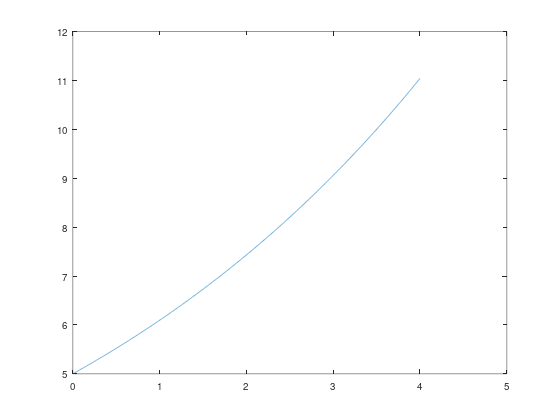

In [7]:
euler

Before the loop, we create two vectors, `T` and `Y`, and set the first element of each with the initial conditions; `dt`, which is the size of the time steps, is 0.1 hours.

Inside the loop, we compute the growth rate based on the current time, `T(i)`, and population, `Y(i)`. You might notice that the rate depends only on population, but we pass time as an input variable anyway, for reasons you’ll see soon.

After computing the growth rate, we add an element both `T` and `Y`. Then, when the loop exits, we plot `Y` as a function of `T`.

If you run the code, you should get a plot of population over time, as shown in Figure 9.1.

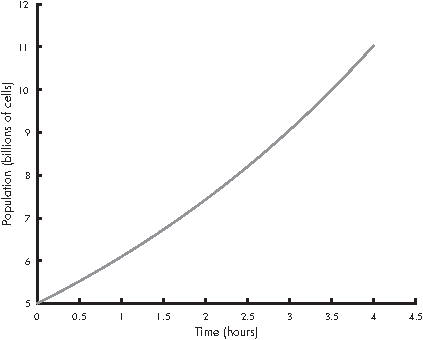

*Figure 9.1: Solution to a simple differential equation by Euler’s method*

As you can see, the population doubles in a little less than 4 hours.

## Solving ODEs with ode45

A limitation of Euler’s method is that it assumes that the derivative is constant between time steps, and that’s not generally true. Fortunately, there are better methods that estimate the derivative between time steps, and they are much more accurate.

MATLAB provides a function called `ode45` that implements one of these methods. In this section I’ll explain how to use it; you can read more about how it works in “How ode45 Works” in Section 15.1.

In order to use `ode45`, you have to write a function that evaluates $dy/dt$ as a function of $t$ and $y$. Fortunately, we already have one, called `rate_func`:

In [8]:
function res = rate_func(t, y)
   a = 0.2;
   dydt = a * y;
   res = dydt;
end

We can call `ode45` from the Command Window like this:

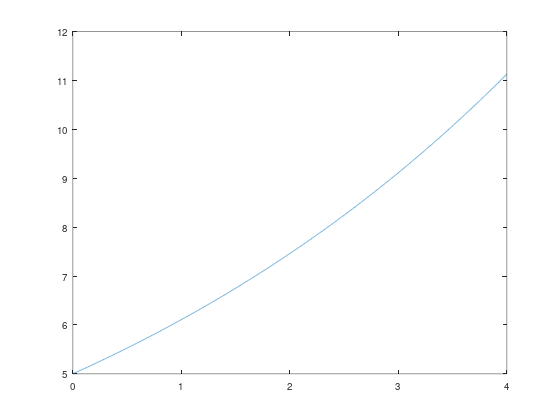

In [9]:
[T, Y] = ode45(@rate_func, [0, 4], 5);
plot(T, Y)

The first argument is a function handle, as we saw in Chapter 7. The second argument is the time interval where we want to evaluate the solution; in this case the interval is from $t=0$ to $t=4$ hours. The third argument is the initial population, 5 billion cells.

The `ode45` function is the first function we’ve seen that returns *two* output variables. In order to store them, we have to assign them to two variables, `T` and `Y`. Figure 9.2 shows the results.

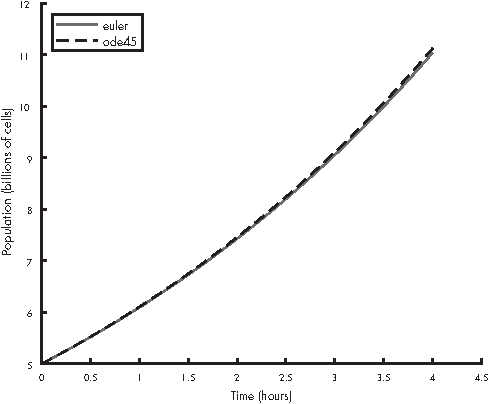

*Figure 9.2: Solutions to a simple differential equation using Euler’s method and `ode45`*

The solid line is the estimate we computed with Euler’s method; the dashed line is the solution from `ode45`.

For the first 2–3 hours, the two solutions are visually indistinguishable. During the last hour, they diverge slightly; at 4 hours, the difference is less than 1 percent.

For many purposes, the difference between Euler’s method and `ode45` is the least of our worries. In this example, we probably don’t know the initial population with perfect accuracy or the growth constant, `a`. Also, the assumption that the growth rate only depends on population is probably not true. Any of these modeling errors could be bigger than 1 percent.

However, for some problems, Euler’s method can be off by a lot more than 1 percent. In those cases `ode45` is almost always more accurate, for two reasons: first, it computes the rate function several times per time step; second, if the time step is too big, `ode45` can detect the problem and shrink the time step. For more details, see “How ode45 Works” in Section 15.1.

## Time Dependence

Looking at `rate_func` in the previous section, you might notice that it takes `t` as an input variable but doesn’t use it. That’s because the growth rate does not depend on time—bacteria don’t know what time it is.

But rats do. Or, at least, they know what season it is. Suppose that the growth rate for rats depends on the current population *and* the availability of food, which varies over the course of the year. The differential equation might be something like

$$\frac{dy}{dt}(t) = a y(t) \left(1 - \cos (\omega t) \right)$$

where $t$ is time in days and $y(t)$ is the population at time $t$. Because the growth rate depends on time, this differential equation is *time dependent*.

The variables $a$ and $\omega$ are *parameters*, which are values that quantify a physical aspect of the scenario. Parameters are often constants, but in some models they vary in time.

In this example, $a$ characterizes the reproductive rate per day, and $\omega$ is the frequency of a periodic function that describes the effect of varying food supply on reproduction.

We’ll use the values $a = 0.002$ and $\omega = 2 \pi/365$ (one cycle per year). The growth rate is lowest at $t=0$, on January 1, and highest at $t=365/2$, on June 30.

Now we can write a function that evaluates the growth rate:

In [10]:
function res = rate_func(t, y)
    a = 0.002;
    omega = 2*pi / 365;
    res = a * y * (1 - cos(omega * t));
end

To test this function, I put it in a file called *rat_pop.m* with a top-level function called `rat_pop`:

In [11]:
function res = rat_pop()
    t = 365/2;
    y = 1000;
    res = rate_func(t, y);
end

The top-level function assumes, for purposes of testing, that there are 1000 rats at $t=365/2$ (June 30) and computes the growth rate under those conditions.

We can run the top-level function like this:

In [12]:
r = rat_pop

r = 4


Under these conditions, the growth rate is 4 new rats per day.

Now that we’ve tested `rate_func`, we can use `ode45` to solve the differential equation. Here’s how to call it from the top-level function in *rat_pop.m*:

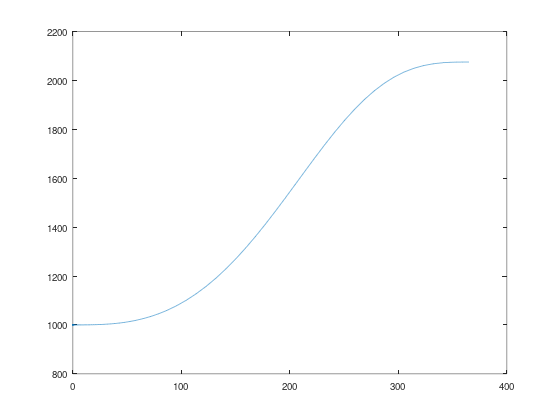

In [13]:
[T, Y] = ode45(@rate_func, [0, 365], 1000);
plot(T, Y)

The first argument is a function handle, again. The second argument is the interval we are interested in, a duration of one year, expressed in units of days. The third argument is the initial population, $y(0) = 1000$.

Figure 9.3 shows the results.

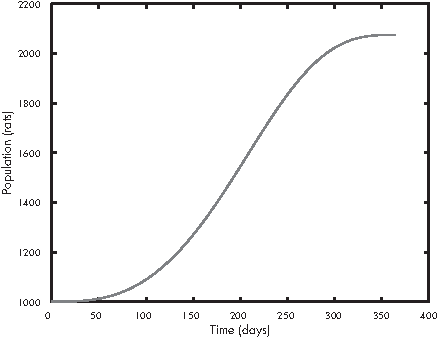

*Figure 9.3: Solutions to a simple differential equation by Euler’s method and `ode45`*

The population grows slowly during the winter, quickly during the summer, and then slowly again in the fall.

To see the population at the end of the year, you can display the last element of `Y`:

In [14]:
Y(end)

ans = 2075.1


That’s a little more than 2000 rats, so the population roughly doubles in one year.

The index here is `end`, which is a special word in MATLAB that means “the index of the last element.” You can use it in an expression, so `Y(end - 1)` is the second-to-last element of `Y`.

## What Could Go Wrong?

Don’t forget the `@` on the function handle. If you leave it out, like:

```
[T, Y] = ode45(rate_func, [0, 365], 1000)
```

MATLAB treats the first argument as a function call and calls `rate_func` without providing arguments. Then you get an error message:

In MATLAB, the error message is:

```
Not enough input arguments.

Error in rat_pop>rate_func (line 18)
    res = a * y * (1 - cos(omega * t));

Error in rat_pop (line 6)
    [T, Y] = ode45(rate_func, [0, 365], 1000);
```

In Octave, it is:

```
error: 'y' undefined
```

Also, the rate function you write has to take two input variables, `t` and `y`, in that order, and return one output variable, `res`.

If you’re working with a rate function like:

$$\frac{dy}{dt}(t) = a y(t)$$ you might be tempted to write this:

In [15]:
function res = rate_func(y)        % WRONG
    a = 0.002;
    res = a * y;
end

But that would be wrong. So very wrong. Why? Because when `ode45` calls `rate_func`, it provides two arguments. If you only take one input variable, you’ll get an error. So you have to write a function that takes `t` as an input variable, even if you don’t use it:

In [16]:
function res = rate_func(t, y)     % RIGHT
    a = 0.002;
    res = a * y;
end

Another common error is to write a function that doesn’t make an assignment to the output variable. If you write something like:

In [17]:
function res = rate_func(t, y)
    a = 0.002;
    omega = 2*pi / 365;
    r = a * y * (1 - cos(omega * t));    % WRONG
end

and then call it from `ode45`, you get

In MATLAB, the error message is:

```
Output argument "res" (and maybe others) not assigned during call
to "rate_func".
```

In Octave, it is:

```
error: value on right hand side of assignment is undefined
```

In [18]:
% In this notebook each cell starts a new figure, so the examples below
% call this function first to draw the two solutions in Figure 9.2 again.
function plot_solutions()
    [T, Y] = ode45(@(t, y) 0.2 * y, [0, 4], 5);
    T_euler = 0:0.1:4;
    Y_euler = 5 * 1.02 .^ (0:40);    % Euler's method with dt = 0.1
    plot(T_euler, Y_euler, T, Y, '--')
end

I hope these warnings save you some time debugging.

## Labeling Axes

The plots in this chapter have labels on the axes, and one of them has a legend, but I didn’t show you how to do that. Let’s do it now.

The functions to label the axes are `xlabel` and `ylabel`:

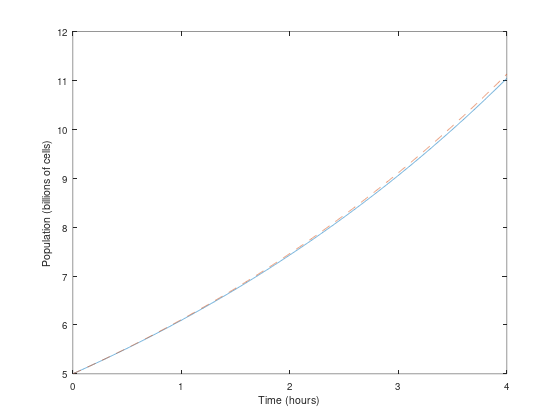

In [19]:
plot_solutions
xlabel('Time (hours)')
ylabel('Population (billions of cells)')

The function to generate a legend is `legend`:

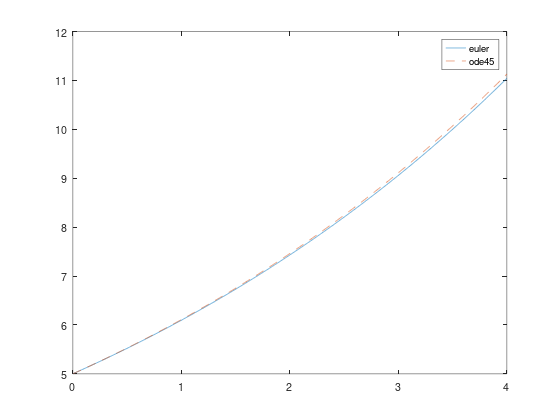

In [20]:
plot_solutions
set(gca, 'fontsize', 11)    % works around a bug in the browser version of Octave
legend('euler', 'ode45')

The arguments are the labels for the lines, in the order they were drawn. Usually the legend is in the upper-right corner, but you can move it by providing an optional argument called `Location`:

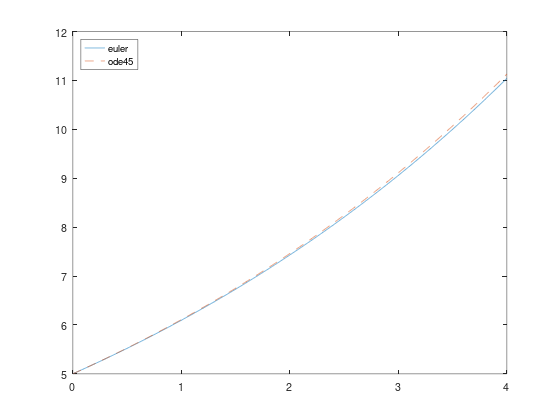

In [21]:
plot_solutions
set(gca, 'fontsize', 11)    % works around a bug in the browser version of Octave
legend('euler', 'ode45', 'Location', 'northwest')

Finally, save the figures using `saveas`:

```
saveas(gcf, 'runge.eps', 'epsc')
```

The first argument is the figure we want to save; `gcf` is a MATLAB command that stands for “get current figure,” which is the figure we just drew. The second argument is the filename. The extension specifies the format we want, which is Encapsulated PostScript (*.eps*). The third argument tells MATLAB what driver to use. The details aren’t important, but `epsc` generates figures in color.

## Chapter Review

This chapter introduced *differential equations (DE)*, which are equations that describe the derivatives of an unknown function. In an *ordinary differential equation (ODE)*, all derivatives are taken with respect to the same variable, as opposed to a *partial differential equation (PDE)*, which includes derivatives with respect to more than one variable.

A *first-order DE* includes only first derivatives, and a *linear DE* includes no products or powers of the function and its derivatives. A differential equation is *time dependent* if the rate function depends on time.

When we solve a differential equation numerically, the *time step* is the interval in time between successive elements of the solution. A *parameter* is a value that appears in a model to quantify some physical aspect of the scenario being modeled.

Until now we have only put one function in each M-file, but in this chapter we wrote a *top-level function*, which is the first function in an M-file, and a *helper function*, which is any function in an M-file that is not the top-level function.

In the next chapter, we’ll solve *systems* of ODEs, which are used to describe physical systems with multiple parts that interact. But first, here’s an exercise where you can apply what you’ve learned so far.

## Exercise

Before you go on, you might want to work on the following exercise.

**Exercise 9.1.**

Suppose that you’re given an 8-ounce cup of coffee at 90°C. You have learned from bitter experience that the hottest coffee you can drink comfortably is 60°C.

If the temperature of the coffee drops by 0.7°C during the first minute, how long will you have to wait to drink your coffee?

You can answer this question with Newton’s Law of Cooling (see <https://greenteapress.com/matlab/newton>):

$$\frac{dy}{dt}(t) = -k (y(t) - e)$$

where $y(t)$ is the temperature of the coffee at time $t$, $e$ is the temperature of the environment, and $k$ is a parameter that characterizes the rate of heat transfer from the coffee to the environment.

Let’s assume that $e$ is 20°C and constant; that is, the coffee does not warm up the room.

Let’s also assume $k$ is constant. In that case, we can estimate it based on the information we have. If the temperature drops 0.7°C during the first minute, when the coffee is 90°C, we can write

$$-0.7 = -k (90 - 20)$$

Solving this equation yields $k = 0.01$.

Here are some suggestions for getting started:

1.  Create a file named *coffee.m* and write a function called `coffee` that takes no input variables. Put a simple statement like `x = 5` in the body of the function and invoke `coffee` from the Command Window.

2.  Add a helper function called `rate_func` that takes `t` and `y` and computes $dy/dt$. In this case, `rate_func` does not actually depend on $t$; nevertheless, your function has to take $t$ as the first input variable in order to work with `ode45`.

3.  Test your function by adding a line like `rate_func(0, 90)` to `coffee`, then call `coffee` from the Command Window. Confirm that the initial rate is -0.7°C/min.

4.  Once you get `rate_func` working, modify `coffee` to use `ode45` to compute the temperature of the coffee for 60 minutes. Confirm that the coffee cools quickly at first, then cools more slowly, and reaches room temperature after about an hour.

5.  Plot the results and estimate the time when the temperature reaches 60°C.

In [22]:
% Solution

% Use ode45 to predict coffee temperature.

function res = coffee()
    t = 0;
    y0 = 90;
    r = rate_func(t, y0)

    [T, Y] = ode45(@rate_func, [0, 60], y0);
    plot(T, Y)
    xlabel('Time (minutes)')
    ylabel('Temperature (C)')

    Y(end)
end

function res = rate_func(t, y)
    k = 0.01;
    e = 20;
    res = -k * (y - e);
end

r = -0.7000
ans = 58.417


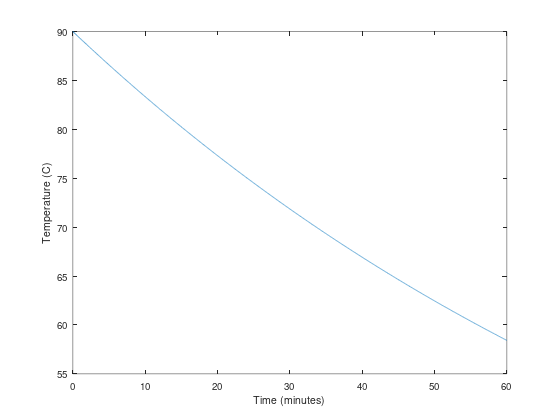

In [23]:
% Solution

coffee